# LASSI - Power Efficiency

***OLLAMA API*** + ***Argo Gateway API*** Jupyter Notebook version

+ No translation
+ Source code scripts from:
https://github.com/zjin-lcf/HeCBench/tree/master/src

Power measurements: https://pypi.org/project/nvidia-ml-py/  (pynvml)

In [1]:
import pynvml
pynvml.nvmlInit()
print(pynvml.nvmlSystemGetDriverVersion())
pynvml.nvmlShutdown()

560.35.05


## Setup

In [1]:
import os
import json
from datetime import datetime

# Import LASSI modules
import lassi.llm_config
# import lassi.pipeline # The Pipeline script calls the other LASSI libraries not imported here.
import lassi.pipeline_v2
from lassi.format_colors import color
from lassi.prompt_dictionary import PromptDictionary

# Enable the autoreload extension
%load_ext autoreload
%reload_ext autoreload

# Reload all modules imported with %aimport every time before executing subsequent code.
%autoreload 1

# We need to reload the libraries while under development
%aimport lassi.format_colors
%aimport lassi.prompt_dictionary
%aimport lassi.llm_config
%aimport lassi.llm_methods
# %aimport lassi.pipeline
%aimport lassi.pipeline_v2
%aimport lassi.get_power
%aimport lassi.argostream_curl

## Code Generation Experiment - Setup + Run

_____
***STEP 1/2: Input experimental configuration parameters in the following method.***

In [2]:
def experimental_setup():
    # Load config file with source application names and input parameters
    with open("source_apps.json", "r") as f:
        source_apps = json.load(f)
    
    """
    [1] ENTER APPLICATION FOLDER NAME FROM HeCBench
        >> Execution input parameters provided.
    
    HeCBench apps:
    -- matrix-rotate ["30000", "100"]  ["10000", "1"]  # Usage: %s <matrix size> <repeat>
    -- jacobi [""] (none required)
    -- layout ["2500"] ["1"]
    -- atomicCost ["16", "10"] ["1"]
    -- segment-reduce ["16384", "100"] (a replacement for atomicCost, same "Data compression and reduction" category in HeCBench)
    -- dense-embedding ["100000", "128", "100"] ["10000", "8", "1"]
    -- pathfinder ["100000", "10000", "2500"] ["100000", "1000", "5"] ["10000", "1000", "1000"]  # Usage: <column length> <row length> <pyramid_height>
    -- bsearch ["8388608", "1000"] ["10000", "1"]  # Usage: <number of elements> <repeat>
    -- entropy ["8192", "8192", "500"] ["10000", "1024", "1"]  # Usage: <width> <height> <repeat>
    -- colorwheel ["10000", "256", "500000"] ["10000", "8", "1"]  # Usage: <range> <size> <repeat>
    -- randomAccess ["10"] ["1"]  # Usage: <repeat>
    -- lid-driven-cavity [""]

    Altis apps:
    -- level1/bfs ["--size 3"]
    -- level2/raytracing [""]
    -- level2/mandelbrot ["--imageSize 1024 --iterations 100000"]
    
    """

    # Enter source application to process through LASSI
    source_collection = "HeCBench"
    source_app = "stu-matrix-rotate"

    """
    Valid source code folder names (under source_codes):
    1. HeCBench
    2. altis/src/cuda
    """
    source_folder = source_apps[source_collection]["source_folder"]  # "altis/src/cuda/level2"    #  "HeCBench" "altis/src/cuda/level1"
    app_folder_name = source_apps[source_collection][source_app]["app_folder"]
    app_name = app_folder_name + "-cuda_main"
    build_script = False  # False (for HeCBench)

    
    """
    [2] SELECT THE CODE TRANSLATION MAPPING DIRECTION EXPERIMENT CONFIGURATION
    
    CUDA -- OMP -- HIP -- SYCL -- FORTRAN
    """   
    # These should be the same if *not* doing translation.
    source_lang = "CUDA"
    target_lang = "CUDA"

    test_code_first = True  # True or False
    
    # TOGGLE USE CODE KNOWLEDGE CONTEXT FOR TARGET
    # THESE WILL NO LONGER BE OPTIONS
    use_context = False  # True or False -- NOT USED IN v2
    use_self_prompting = False  # True or False -- NOT USED IN v2
    use_context_summaries_only = True  # True or False
    baseline_oneshot_goal = True  # True or False -- NOT USED IN v2
    few_shot_learning = False  # True or False

    # TOGGLE USE OF POWER MEASUREMENT DURING EXE
    power_measure = False  # True or False
    vary_llm_temp = True  # True or False

    # TOGGLE ENERGY EFFICIENCY SELF-CORRECTION FEEDBACK
    yes_power_feedback = True  # True or False

    # ASSIGN CODE COMPILE COMMAND
    code_build_script = ""
    code_compiler = ""
    code_compiler_kwds = ""
    if source_lang == "CUDA":
        if build_script:
            code_build_script = "build_" + app_name
        else:
            code_compiler = "nvcc"
            code_compiler_kwds = "-std=c++14 -Xcompiler -Wall -arch=sm_80 -O3"
            # -arch=sm_70 for aiops01 GPU (Argonne)  # -arch=sm_80 for A100s
            # -arch=sm_60 for P100
        if yes_power_feedback:
            context_knowledge_selection = "cuda_optimization_summary"
            context_fewshot_examples = "cuda_c_few_shot_examples"
        else:
            context_knowledge_selection = "cuda"
    elif source_lang == "OMP":
        # Linux_x86_64 or Linux_aarch64
        code_compiler = "g++" # "/opt/nvidia/hpc_sdk/Linux_aarch64/2024/compilers/bin/nvc++"  # 
        code_compiler_kwds = "-fopenmp -O3" # "-Wall -O3 -Minfo -mp=gpu -gpu=cc80"  # -c
        context_knowledge_selection = "omp"

    # TOGGLE EXECUTE PIPELINE
    yes_execute = True  # True / False
    if yes_execute:
        # Enter execution input parameters, if needed
        # A list of parameter string values, e.g., ["10000", "1"]
        exe_input_parameters = source_apps[source_collection][source_app]["app_params"]
    else:
        exe_input_parameters = [""]

    
    """
    [3] SELECT THE LLM TO USE FOR THE CODE TRANSLATION EXPERIMENT
    """
    # SELECT A MODEL
    
    # -- FROM ARGO:
    # model = "gpt35"  # (max token = 4096)
    # model = "gpt35large"  # (max token = 16384)
    # model = "gpt4large"  # (max token = 32768)
    # model = "gpt4turbo"  # (max token = 128000)
    # model = "gpto1mini"  # (max token = 128000)
    # model_coder = "gpto1mini"  # (max token = 128000)
    # model = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4o"  # (max token = 128000)
    # model_coder = "gpt4olatest"  # (max token = 128000)
    model = "gpto3mini"  # (max token = 200000)
    model_coder = "gpto3mini"  # (max token = 200000)
    model_judge = "gpto3mini"  # (max token = 200000)

    # -- FROM OLLAMA
    # model = "qwq:latest"  # (max token = 128000)
    # model_coder = "qwen2.5-coder:32b"  # (max token = 32768)
    # model_judge = "qwq:latest"  # (max token = 128000)
    # model = "qwq:latest"  # (max token = 131072)
    # model = "gemma3:27b"  # crashing on code gen
    # model_coder = "gemma3:27b"
    # model = "granite3.2:8b-instruct-q8_0"
    # model_coder = "granite-code:34b-instruct-q8_0"
    # model = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-r1:70b"  # (max token = 128000)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model_coder = "deepseek-coder-v2:16b"  # (max token = 131072)
    # model = "dolphin3"  # (max token = 131072)
    # model = "llama3.3:latest"  # (max token = 131072)
    # model = "phi4" # (max token = 16384)
    # model_coder = "codestral:22b"  # (max token = 32768)
    # model = "codestral:22b-v0.1-q8_0"  # (max token = 32768)
    # model = "wizardcoder:33b-v1.1-q8_0"  # (max token = 16384)
    # model_coder = "deepseek-coder:33b-instruct-q8_0"  # (max token = 16384)
    # model = "deepseek-coder-v2:16b-lite-instruct-fp16"  # (max token = 128000)
    # model = "deepseek-coder-v2:16b-lite-instruct-q8_0"
    # model = "phi3:14b"  # (max token = 131072)
    # model_judge = "llama3.3:70b"  # (max token = 128000)
  
    # Set maximum context token count size for selected LLM:
    num_ctx = 200000
    num_ctx_coder = 200000

    # Needed only for Argo endpoints
    uri = "remote"  # local

    # ASSIGN LLM API SOURCE:
    if model in ["gpt35", "gpt35large", "gpt4", "gpt4large", "gpt4turbo", "gpt4o", "gpto1preview", "gpto1mini", "gpto3mini"]:
        llm_source = "argo"
    elif "GGUF" in model:
        llm_source = "lmstudio"
    else:
        llm_source = "ollama"

    """
    [4] SET ADDITIONAL PIPELINE PARAMETERS
    """
    experiment = "_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_stu-matrot_" + llm_source + "_ee_hecb_selfcontext"  # Assign any label for experiment name.
    display_response = True
    test_with_error = False
    generate_test_case = False

    # Unload any previously loaded LLMs in the Ollama server 
    # (clear out the memory)
    if llm_source == "ollama":
        lassi.llm_config.unload_ollama_model(model)
        lassi.llm_config.unload_ollama_model(model_coder)

    return (app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder, llm_source, use_context, use_context_summaries_only,
            few_shot_learning, context_knowledge_selection, source_folder, code_compiler, code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters,
            experiment, display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp)

_____
***STEP 2/2: Run the following block to implement the pipeline with the configuration parameters.***


***** EXPERIMENT CONFIGURATION SUMMARY *****

Date-time: 04-04-2025_t17_06_31
Application: stu-matrix-rotate

EE Refactoring: CUDA_ee

LLM Source: argo
Model: gpto3mini
Model coder: gpto3mini
System Prompt Index: CUDA
Code file template: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_stu-matrot_argo_ee_hecb_selfcontext

LLM System Prompt: 

You are an expert C++/CUDA engineer. Your goal is to refactor provided CUDA C++ code for energy efficiency by reducing GPU and CPU power consumption without losing any functionality of the original code. You must also carefully read and incorporate the best practices from the provided background documents. You always surround your generated code with the three characters ```.

Power measurement: False


***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****


----- GPU Memory Status:
 GPU 0: 5908 MiB used, 76011 MiB free, 81920 MiB total

----- GPU 

Waiting for the system to settle down for 1 seconds...: 100%|████████████████████████████████████████████| 1/1 [00:01<00:00,  1.00s/it]


Working directory: source_codes/HeCBench/stu-matrix-rotate
Execute command: ['./stu-matrix-rotate-cuda_main', '30000', '100']


----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

Average kernel execution time: 0.063353 (s)

----- < END: Standard Output > -----


Program executed successfully!


Measure system idle power...
Duration for idle time measurement: 0
Error querying power: Not Supported
GPU power data has been written to idle__gpu_net_power_results.csv


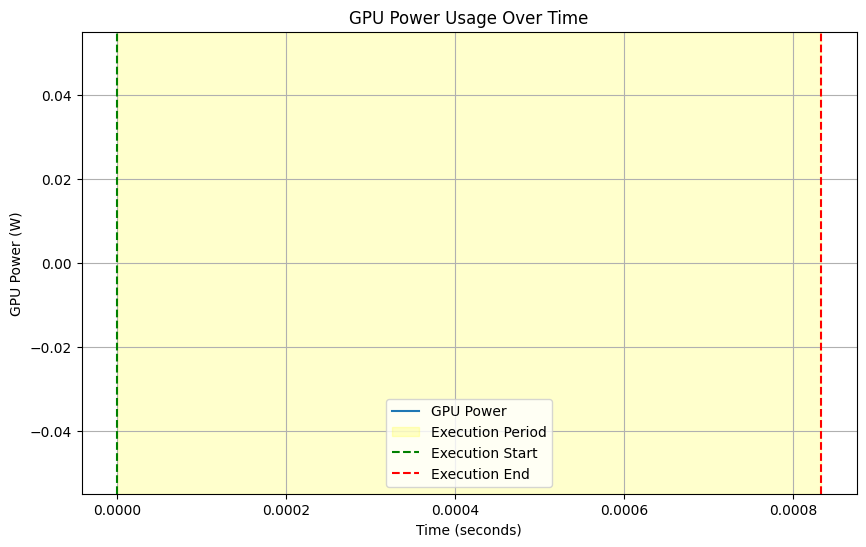

Start time: 0 -- End time: 0.001
Not enough data points to calculate energy consumption.
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000000 kWh
  0.0000 Wh
  0.00 J
Average GPU power: 0.00 W +/- 0.00 
 with sample standard deviation.
Total Energy During Exe Runtime:   0.00 J
Code execution duration:  0.00 seconds
----------------------------------------------------------------------------------------------------------------------------------------


----- STARTING FIRST STAGE: ZERO-SHOT BASE LLM REFACTORING -----


----- GPU Memory Status:
 GPU 0: 5908 MiB used, 76011 MiB free, 81920 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, [N/A], P0


----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt without code, token count: 24): 


--> ... initial zero-shot attempt: prompt the LLM to generate code.



----- STARTING CODE GENERATION -----


=====> VERIFY THE PROMPTING <=====

TEMP



----- THE GENERATED CODE -----

(hidden)


Compile command: ['nvcc', '-std=c++14', '-Xcompiler', '-Wall', '-arch=sm_80', '-O3', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_stu-matrot_argo_ee_hecb_selfcontext_04-04-2025_t17_06_31.cu', '-o', 'generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_stu-matrot_argo_ee_hecb_selfcontext_04-04-2025_t17_06_31']

Compilation of code successful!


Execute file: generated_codes/argo_gpto3mini/promptset_CUDA/stu-matrix-rotate-cuda_main_ee_refactorcode_CUDA_exp_tTEST-SYSCONTENT-idlecorr_pipelineV2_o3mini_stu-matrot_argo_ee_hecb_selfcontext_04-04-2025_t17_06_31


Waiting for the system to settle down for 5 seconds...:  40%|█████████████████▌                          | 2/5 [00:02<00:04,  1.39s/it]


KeyboardInterrupt: 

In [3]:
prompts = PromptDictionary()

# Store the current home working directory (needed for code execution)
original_home_directory = os.getcwd()


# COLLECT THE EXPERIMENT CONFIGURATIONS
(
    app_folder_name, app_name, source_lang, target_lang, model, model_coder, model_judge, num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, context_knowledge_selection, source_folder, code_compiler,
    code_compiler_kwds, build_script, code_build_script, yes_execute, exe_input_parameters, experiment,
    display_response, test_with_error, generate_test_case, power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp
) = experimental_setup()

# IMPORT CONTEXT KNOWLEDGE FOR TARGET PROGRAMMING LANGUAGE
input_context = "[BACKGROUND KNOWLEDGE: CUDA C++ PROGRAMMING BEST PRACTICES] " + prompts.get_codeknowledge("cuda") + "\n\n"  # [/END GENERAL CUDA PROGRAMMING CONTEXT]
input_context = input_context + "[BACKGROUND KNOWLEDGE: CUDA C++ OPTIMIZATION GUIDE] " + prompts.get_codeknowledge(str(context_knowledge_selection)) + "\n\n"  #  [/END CUDA OPTIMIZATION CONTEXT]


# DEFINE PROMPT TEMPLATES
# TODO: MOST TASK PROMPT TEMPLATES WILL BE HANDLED BY THE PIPELINE METHODS
system_prompt_selection_index = source_lang + "_ee"  # "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
this_llm_system_prompt = prompts.get_system_prompt(str(system_prompt_selection_index))

coderefactor_prompt_selection_index = source_lang  # + "_to_" + target_lang  # Select which prompt to use from the prompt dictionary
if (not baseline_oneshot_goal and use_self_prompting):
    this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index))
else: 
    if use_context:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline"))
    else:
        this_llm_refactoredcode_prompt = prompts.get_code_ee_refactoring_prompt(str(coderefactor_prompt_selection_index + "_baseline_nocontext"))

# LOAD INPUT CODE TO TRANSLATE
input_code_folder = source_folder + "/" + app_folder_name + "/"
if build_script:
    input_code_filename = app_name
else:
    input_code_filename = app_folder_name + "-" + source_lang.lower() + "_main"
if source_lang == "OMP" or source_lang == "SYCL":
    input_code_extension = "cpp"
elif source_lang == "CUDA" or source_lang == "HIP":
    input_code_extension = "cu"
source_file_directory = "source_codes/" + input_code_folder
source_file_path = source_file_directory + input_code_filename + "." + input_code_extension
with open(source_file_path, 'r') as file:
    input_code = file.read()
file.close()


# SPECIFY OUTPUT CODE SAVE
if build_script:
    output_code_directory = "generated_codes/" + source_folder + "/" + app_folder_name
    output_code_file_name = app_name
else:
    output_code_directory = "generated_codes/" + llm_source + "_" + model.replace('/', '--') + "/promptset_" + str(coderefactor_prompt_selection_index)
    output_code_file_name = input_code_filename + "_ee_refactorcode_" + source_lang + "_exp" + experiment


now = datetime.now()
dt_string = now.strftime("%m-%d-%Y_t%H_%M_%S")

# CREATE METADATA RECORD CONTENT
meta_data_file = "***** EXPERIMENT CONFIGURATION SUMMARY *****\n"
meta_data_file += "\nDate-time: " + dt_string
meta_data_file += "\nApplication: " + app_folder_name
meta_data_file += "\n\nEE Refactoring: " + system_prompt_selection_index
# meta_data_file += "\nTranslate from: " + input_code_extension
# meta_data_file += "\nTranslate to: " + translated_code_extension
meta_data_file += "\n\nLLM Source: " + llm_source
meta_data_file += "\nModel: " + model
meta_data_file += "\nModel coder: " + model_coder
meta_data_file += "\nSystem Prompt Index: " + str(coderefactor_prompt_selection_index)
meta_data_file += "\nCode file template: " + output_code_directory + "/" + output_code_file_name
meta_data_file += "\n\nLLM System Prompt: " + "\n\n" + this_llm_system_prompt
# meta_data_file += "\n\nLLM Prompt for Code Generation: " + "\n\n" + this_llm_refactoredcode_prompt
meta_data_file += "\n\nPower measurement: " + str(power_measure)

# Display metadata
print("\n" + meta_data_file + "\n")

print("\n" + color.BOLD + "***** BEGIN THE LASSI ENERGY EFFICIENCY PIPELINE (v2) *****" + color.END + "\n")

# RUN PIPELINE
complete = lassi.pipeline_v2.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_refactoredcode_prompt,
    llm_source, 
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    # arrayormatrix_size_range,
    # thread_count_range,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    input_context,
    input_code,
    # target_code,
    target_lang,
    input_code_extension,
    source_lang,
    code_compiler,
    code_compiler_kwds,
    build_script,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp
)

# Reset to original working directory
os.chdir(original_home_directory)

if complete:
    print("\n\n" + color.GREEN + color.BOLD + "***** LASSI PIPELINE COMPLETED *****\n\n" + color.END)
else:
    print("\n\n" + color.RED + color.BOLD + "***** LASSI PIPELINE FAILED TO COMPLETE *****\n\n" + color.END)